In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import sys

# Resolve the dataset relative to the repository, regardless of the notebook/Jupyter cwd.
candidates = [
    Path.cwd() / "data" / "raw" / "SMSSpamCollection",
    Path.cwd().parent / "data" / "raw" / "SMSSpamCollection",
]
data_path = next((path for path in candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError("SMSSpamCollection was not found under data/raw")
repo_root = data_path.parents[2]
sys.path.insert(0, str(repo_root / "src"))
for directory in ("data/processed", "tables", "figures"):
    (repo_root / directory).mkdir(parents=True, exist_ok=True)

## 1. Data loading, profiling

### 1.1 Read file

In [2]:
# quoting=3 is required because many messages contain double quotes.
raw = pd.read_csv(data_path, sep="\t", header=None,
                  names=["label", "text"], encoding="utf-8", quoting=3)
print(raw.shape)
print("\n", raw.dtypes)
print("\n", raw["label"].value_counts())
print("\n", raw["text"].str.contains("£").sum()) # >0 nghĩa là £ đọc đúng

(5574, 2)

 label    str
text     str
dtype: object

 label
ham     4827
spam     747
Name: count, dtype: int64

 258


### 1.2  Profiling

#### 1.2.2 Variable meaning

In [3]:
raw.label.unique() 

<StringArray>
['ham', 'spam']
Length: 2, dtype: str

#### 1.2.3 Completeness

In [4]:
raw.isna().sum()


label    0
text     0
dtype: int64

In [5]:
(raw.text.str.strip()=="").sum()

np.int64(0)

#### 1.2.4 Validity

In [6]:
# Kiểm tra độ dài min/max
raw.text.str.len().describe()

count    5574.000000
mean       80.478292
std        59.848302
min         2.000000
25%        36.000000
50%        62.000000
75%       122.000000
max       910.000000
Name: text, dtype: float64

In [7]:
raw.text.str.contains(r"[^\x00-\x7F]").sum() # Số ký tự ngoài ASCII

np.int64(483)

#### 1.2.5 Consistency

In [8]:
# Độ dài hai lớp khác nhau thế nào
raw.groupby('label').text.apply(lambda s: s.str.len().median())

label
ham      52.0
spam    149.0
Name: text, dtype: float64

#### 1.2.6 Distribution

In [9]:
# Tỷ lệ Spam (mất cân bằng lớp)
raw.label.value_counts(normalize=True)

label
ham     0.865985
spam    0.134015
Name: proportion, dtype: float64

### 1.3 Loại trùng chính xác

In [10]:
raw["key"] = (raw["text"].str.lower().str.strip().str.replace(r"\s+", " ", regex=True))
nlab = raw.groupby("key")["label"].nunique()
conflict = nlab[nlab > 1].index # cùng văn bản, khác nhãn
sizes = raw.groupby("key").size()
print("nhóm trùng:", (sizes > 1).sum(), "| nhóm mâu thuẫn nhãn:", len(conflict))

clean = raw[~raw["key"].isin(conflict)] # loại cả nhóm mâu thuẫn
clean = clean.drop_duplicates(subset="key", keep="first")[["label", "text"]].reset_index(drop=True)
clean.to_csv(repo_root / "data/processed/sms_dedup.csv", index=False)

raw = raw[["label", "text"]] # corpus gốc, dùng cho sensitivity S1
print(raw.label.value_counts().to_dict(), clean.label.value_counts().to_dict())

nhóm trùng: 290 | nhóm mâu thuẫn nhãn: 0
{'ham': 4827, 'spam': 747} {'ham': 4517, 'spam': 642}


Không loại near-duplicate (tin Spam chỉ khác số điện thoại hay giải thưởng); chỉ ghi vào Limitations.

### 1.4 Table 1

In [11]:
def summarize(d):
    L = d["text"].str.len(); g = L.groupby(d["label"])
    return pd.DataFrame({"n": d.groupby("label").size(), "median_len": g.median(),
                        "Q1": g.quantile(.25), "Q3": g.quantile(.75)})
    
table1 = pd.concat({"original": summarize(raw), "deduplicated": summarize(clean)})
table1.to_csv(repo_root / "tables/table1.csv")
print(table1)

                       n  median_len     Q1     Q3
             label                                
original     ham    4827        52.0   33.0   93.0
             spam    747       149.0  133.0  157.0
deduplicated ham    4517        53.0   34.0   91.0
             spam    642       148.0  131.0  157.0


### 1.5 Fig. 1: Class distribution

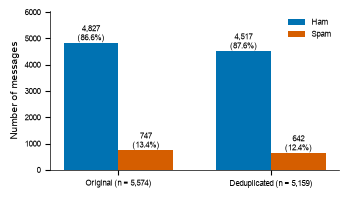

In [ ]:
from figs import fig1_class_distribution
fig = fig1_class_distribution(raw.label.value_counts().to_dict(), clean.label.value_counts().to_dict())
fig.savefig("../figures/fig1_class_distribution.pdf")

## 3. Chạy C2: Mean, DF, Conditional Mean, Δ, phân rã, Top-20 

In [20]:
import warnings; warnings.filterwarnings("ignore")
from nltk.corpus import stopwords
from tfidf_lib import *

cfgs = make_configs(stopwords.words("english"))
top, tab = run_analysis(clean, cfgs["C2"], inference=True, return_full=True)
top.to_csv("../tables/top_terms_C2.csv", index=False)
spam = top[top.side == "Spam"]
ham = top[top.side == "Ham"]


In [21]:
print(spam[["term", "DF_S", "DF_H", "m_S", "m_H", "c_S", "c_H", "delta", "d_prev", "d_int", "D", "LPR"]].round(4))


      term    DF_S    DF_H     m_S     m_H     c_S     c_H   delta  d_prev  \
0        £  0.3271  0.0011  0.0471  0.0002  0.1439  0.1985  0.0468  0.0558   
1     call  0.4315  0.0390  0.0487  0.0066  0.1129  0.1686  0.0421  0.0552   
2        !  0.4704  0.1173  0.0529  0.0185  0.1124  0.1573  0.0344  0.0476   
3     free  0.2243  0.0122  0.0358  0.0024  0.1596  0.1949  0.0334  0.0376   
4      txt  0.1916  0.0029  0.0284  0.0005  0.1482  0.1836  0.0279  0.0313   
5       to  0.6231  0.2555  0.0542  0.0273  0.0870  0.1070  0.0269  0.0357   
6     your  0.3146  0.0739  0.0367  0.0118  0.1168  0.1597  0.0249  0.0333   
7     stop  0.1417  0.0073  0.0247  0.0015  0.1741  0.2101  0.0231  0.0258   
8   mobile  0.1495  0.0029  0.0231  0.0006  0.1546  0.2132  0.0225  0.0270   
9        2  0.2134  0.0567  0.0301  0.0090  0.1410  0.1584  0.0211  0.0235   
10    text  0.1433  0.0144  0.0240  0.0029  0.1672  0.1990  0.0211  0.0236   
11   claim  0.1417  0.0000  0.0208  0.0000  0.1464  0.0000  0.02

In [22]:
print(ham[["term", "DF_S", "DF_H", "m_S", "m_H", "c_S", "c_H", "delta", "d_prev", "d_int", "D", "LPR"]].round(4))

     term    DF_S    DF_H     m_S     m_H     c_S     c_H   delta  d_prev  \
20      i  0.0561  0.3465  0.0045  0.0393  0.0794  0.1134 -0.0348 -0.0280   
21     my  0.0187  0.1240  0.0020  0.0183  0.1046  0.1475 -0.0163 -0.0133   
22     me  0.0358  0.1395  0.0037  0.0197  0.1043  0.1409 -0.0159 -0.0127   
23      ?  0.1854  0.2331  0.0172  0.0326  0.0929  0.1398 -0.0154 -0.0056   
24    i'm  0.0109  0.0748  0.0015  0.0138  0.1362  0.1845 -0.0123 -0.0103   
25     it  0.0389  0.1043  0.0043  0.0163  0.1110  0.1561 -0.0120 -0.0087   
26     ok  0.0078  0.0547  0.0011  0.0130  0.1464  0.2376 -0.0118 -0.0090   
27     in  0.0950  0.1516  0.0097  0.0214  0.1023  0.1411 -0.0117 -0.0069   
28    but  0.0093  0.0874  0.0015  0.0128  0.1552  0.1467 -0.0114 -0.0118   
29   that  0.0343  0.0939  0.0036  0.0149  0.1042  0.1592 -0.0114 -0.0079   
30     so  0.0296  0.0868  0.0030  0.0135  0.1027  0.1554 -0.0104 -0.0074   
31     lt  0.0000  0.0496  0.0000  0.0099  0.0000  0.1997 -0.0099 -0.0050   

In [29]:
show_examples(clean, term="cost", label='ham')

,text
2798,"Hey babe, sorry i didn't get sooner. Gary can ..."
3147,How much it will cost approx . Per month.
129,K..k:)how much does it cost?
3385,How much would it cost to hire a hitman
923,I sent my scores to sophas and i had to do sec...
2423,Can you pls pls send me a mail on all you know...
451,1.20 that call cost. Which i guess isnt bad. M...
190,I'm sorry. I've joined the league of people th...
4949,Sounds better than my evening im just doing my...
818,"Sir, I have been late in paying rent for the p..."


### 3.2 Đọc tin thật

In [30]:
for t in ["free", "call", "£"]: # đổi thành term của bạn, gồm cả phổ biến lẫn hiếm
    print("=====", t)
    print(show_examples(clean, t, "spam", k=10).to_string())


===== free
                                                                                                                                                                  text
4167             Welcome to UK-mobile-date this msg is FREE giving you free calling to 08719839835. Future mgs billed at 150p daily. To cancel send "go stop" to 89123
3550    Mila, age23, blonde, new in UK. I look sex with UK guys. if u like fun with me. Text MTALK to 69866.18 . 30pp/txt 1st 5free. £1.50 increments. Help08718728876
3964     FREEMSG: Our records indicate you may be entitled to 3750 pounds for the Accident you had. To claim for free reply with YES to this msg. To opt out text STOP
1572                                                                                           500 free text msgs. Just text ok to 80488 and we'll credit your account
2585  Great NEW Offer - DOUBLE Mins & DOUBLE Txt on best Orange tariffs AND get latest camera phones 4 FREE! Call MobileUpd8 free on 08000839402 NOW! or 2

### 3.3 Đánh giá H1 (codebook) và H2

In [33]:
lab = top[["side", "term"]].assign(category="") # điền A/B/C/D/E bằng tay theo codebook đã viết ở Bước 0
lab.to_csv("../tables/codebook_labels.csv", index=False)
# sau khi điền xong:
lab = pd.read_csv("../tables/codebook_labels.csv")
print(lab[lab.side == "Spam"].category.value_counts()) # H1: số term thuộc A/B/C so với ngưỡng đã đăng ký
print(lab[lab.side == "Ham"].category.value_counts()) # H1: phía Ham thuộc D
n_prev = (spam.d_prev.abs() > spam.d_int.abs()).sum()
print(f"H2: {n_prev}/20 term Spam có |d_prev| > |d_int| (ngưỡng đã đăng ký: >= 12)")

Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)
H2: 18/20 term Spam có |d_prev| > |d_int| (ngưỡng đã đăng ký: >= 12)
